# 🧪 LAB: Clustering several real datasets

**Motivation**: This lab adopts three contrasting datasets to illustrate how clustering behaves under different real-world conditions—differences in scale, varying cluster separations, and high-dimensional gene expression data. You will put these concepts into practice by applying different clustering methods and evaluating how well they uncover structure in each dataset.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Ethan Ooi, Chloe Wang, Namitha Tholasi"

## Part 1: Clustering arrests by U.S. state (25 points)

The dataset below contains statistics for the 50 U.S. states on four variables recorded in 1973:

- Murder: Arrests for murder (per 100,000 residents)
- Assault: Arrests for assault (per 100,000 residents)
- UrbanPop: Percentage of urban population
- Rape: Arrests for rape (per 100,000 residents)

1. Perform hierarchical clustering using complete linkage and Euclidean distance. Plot the resulting dendrogram.

2. Cut the dendrogram at a height that produces three clusters. Which states belong to each cluster?

3. Repeat the hierarchical clustering, again using complete linkage and Euclidean distance, after scaling all variables to have a standard deviation equal to one.

4. Compare the two clustering solutions. What effect does scaling the variables have on the resulting dendrogram and cluster memberships?
In your opinion, should the variables be scaled in this case before computing inter-observation dissimilarities? Provide a justification for your answer.

In [1]:
import pandas as pd 
dat_1 = pd.read_csv("Lab08-part1_data.csv")
states = dat_1.state.to_list()
X = dat_1.drop(columns="state")
X.head() # This is the dataset to use

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


In [2]:
# USE AS MANY CELLS AS NEEDED

## Part 2: Clustering, genomic data, and cancer (35 points)

Unsupervised techniques are often used to analyze genomic data. In particular, PCA and hierarchical clustering are popular tools.
You will apply these techniques to the dataset below, which consists of gene expression measurements for 64 cancer cell lines across 6,830 genes.

1. Perform hierarchical clustering of the data using complete, single, and average linkage. Use Euclidean distance as the distance metric in all three cases.

In [7]:
import pandas as pd
X = pd.read_csv("Lab08-part2_data.csv") # This is the dataset to use
# These are the labels for each observation
y = pd.read_csv("Lab08-part2_labels.csv").label.to_numpy()
y_data = pd.read_csv("Lab08-part2_labels.csv")

2. Plot the dendrogram for each linkage method. Briefly describe the structure of these dendrograms and comment on the main differences produced by the three linkage criteria.

**I included all 4 because the class code had all four and it's useful for comparison. In single linkage, everything is skewed to one side and it seems that one arm of a cluster is either a cluster within itself or 2-3 clusters. It looks like a single linkage is quick to put an individual observation in one cluster by itself and clusters everything else into another arm, where it repeats the same operation.**

**In complete linkage, I see a more even distribution of observation. Each cluster has many clusters under it. The difference between this and single linkage is that one is more balanced than the other. Unlike the single linage dendrogram, complete linkage does not group 1 observation by itself and and merge the rest, it is based on the shortest max distance of 2 clusters so it prevents instances where physically closer points are merged together despite cluster differences. In a way, the complete linkage looks at a bigger picture than the single linkage.** 

**In average linkage, it is also more balanced than single linkage, however, the wideness of the clusters is like a single linage. I do see one instance of the clusters being skewed on the very right. It looks like only 2 obervations went into 1 arm of a cluster while the rest went to the left arm, signifying a chaining effect. This is like the middle between single and complete linkage.**

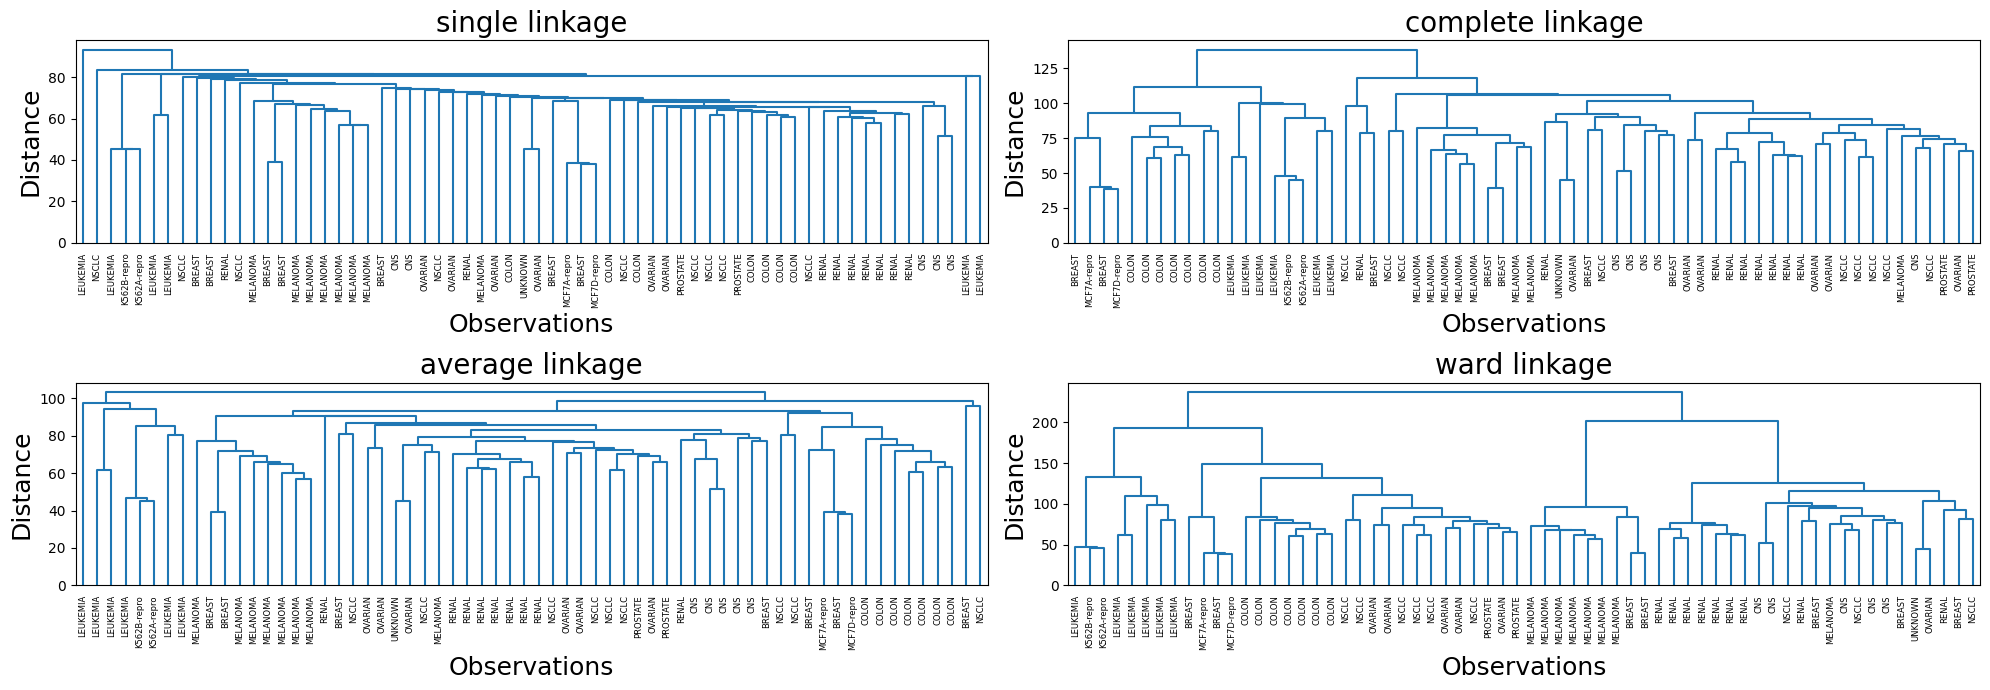

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
fig, axs = plt.subplots(figsize=(20, 7), ncols=2, nrows=2)
axs = axs.flatten()

for method, ax in zip(["single", "complete", "average", "ward"], axs):
    Z = linkage(X, method = method, metric = "euclidean")
    dendrogram(Z, ax = ax, labels = y, color_threshold = 0)
    ax.set_title(f"{method} linkage", size=20)
    ax.set_xlabel("Observations", size=18)
    ax.set_ylabel("Distance", size=18)

plt.tight_layout()

3. Using the known cancer type labels and examining each dendrogram, qualitatively describe how well the samples cluster into distinct cancer types. Do you see clear separation between some types? Which ones appear more mixed?

**In single linkage, the samples cluster more individually rather than in groups. The cancer lables are also spread out more compared to other linkage methods. For example, Leukemia is both the leftmost cluster, the right most cluster, There aren't instances of Leukemia in the center area so thats good and certain types of cancer does tend to group together, like Melanoma and Renal, however, for the most part, we cannot definitively separate cancer types.**

**In complete linkage, the clusters are more pronounced and you can see larger grouping of cancer observations that are the same like Colon, Leukemia, Melanoma, Renal, and NSCLC. There are still some mixed classifications tho like Breast and MCF7A or Renal and Ovarian. Some of the more isolated cancers inslude Prostate and ONS which are sort of on the side.**

**In average linkage, the clusters are kind of like complete linkage in that some cancer types are well defined while other may be difficult to differentiate for the model. For example, ovarian cancer is more spread out between Renal and Prostate cancer. Colon cancer seems the most defined but like in single linkage, there are some cancer types that are spread out more like Breast and NSCLC.**

4. Focusing on complete linkage, plot the dendrogram again and cut it to obtain 4 clusters (e.g., highlight or color the branches). Briefly describe which cancer cell lines cluster together (for example, which cancer types tend to appear in the same cluster). Compute internal validation scores for this 4-cluster partition (e.g., Silhouette score, Calinski–Harabasz index, Davies–Bouldin index).

**Colon and Leukemia seems to cluster well, each predominately taking over one cluster. Though their clusters seem to mix with other different types of cancers. Melanoma, Renal, and ONS for example also seems to all be in the same cluster, however that cluster (purple) has a lot of other cancer types as well.**

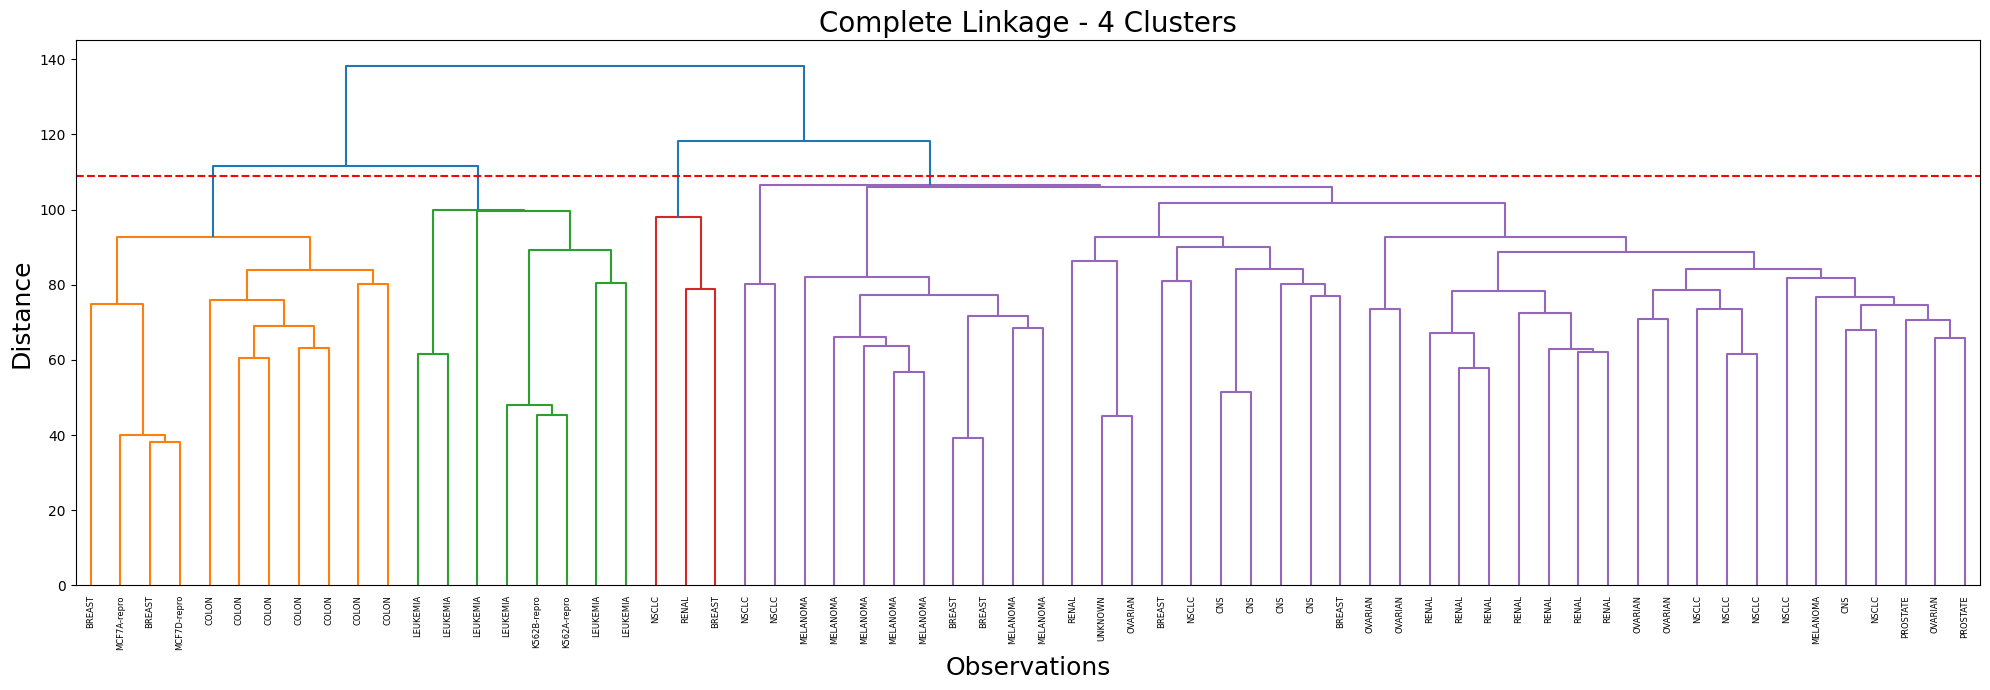

In [31]:
fig, ax = plt.subplots(figsize=(20, 7))

complete_linkage = linkage(X, method = "complete", metric = "euclidean")
# For cutting 4 clusters
hc_labels = fcluster(complete_linkage, t=4, criterion="maxclust")
threshold = (complete_linkage[-4, 2] + complete_linkage[-3, 2]) / 2

dendrogram(complete_linkage, ax = ax, labels = y, color_threshold = threshold)

ax.axhline(y=threshold, color="red", linestyle="--")
ax.set_title("Complete Linkage - 4 Clusters", size=20)
ax.set_xlabel("Observations", size=18)
ax.set_ylabel("Distance", size=18)
plt.tight_layout()
plt.show()


In [32]:
# Internal validation score

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

silhouette = silhouette_score(X, hc_labels)
ch = calinski_harabasz_score(X, hc_labels)
db = davies_bouldin_score(X, hc_labels)

print("Silhouette Score:", silhouette)
print("Calinski-Harabasz Index:", ch)
print("Davies-Bouldin Index:", db)

Silhouette Score: 0.07884960913370792
Calinski-Harabasz Index: 5.010292812643681
Davies-Bouldin Index: 2.1682612357608146


5. Fit a K-Means model with 4 clusters to the same data. Compare this 4-cluster K-Means solution with the 4-cluster hierarchical solution from step 4. How similar are the two partitions? Use at least one external validation metric (e.g., Adjusted Rand Index) to quantify their agreement.

**4-Cluster Hierarchical**
Silhouette Score: 0.07884960913370792\
Calinski-Harabasz Index: 5.010292812643681\
Davies-Bouldin Index: 2.1682612357608146\

**4-Cluster Kmeans**
Silhouette Score: 0.1114481646761114\
Calinski-Harabasz Index: 6.2219018600878595\
Davies-Bouldin Index: 2.1874520321059316\

**Based on the 3 internal scores alone, I think the KMeans solution was better because it has a higher silhouette and calinksi-harabasz score where a higher score indicates better performance. For the Davies-Bouldin Index, lower is better so the hierchical cluster did slightly better, however, the difference is so small it might not be a significant difference. Using the external validation metric of 0.373, we can say that there is moderate agreenment between the hierchical clustering and the kmeans clustering.**

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters = 4)
km_labels = km.fit_predict(X)

km_silhouette = silhouette_score(X, km_labels)
km_ch = calinski_harabasz_score(X, km_labels)
km_db = davies_bouldin_score(X, km_labels)
# External
ari = adjusted_rand_score(hc_labels, km_labels)

print("Silhouette Score:", km_silhouette)
print("Calinski-Harabasz Index:", km_ch)
print("Davies-Bouldin Index:", km_db)
# External
print("Adjusted Rand Index:", ari)

Silhouette Score: 0.1114481646761114
Calinski-Harabasz Index: 6.2219018600878595
Davies-Bouldin Index: 2.1874520321059316
Adjusted Rand Index: 0.37367774910430185


6. Genomic data can be noisy and high-dimensional. To address this, apply PCA to the original data and reduce it to the first 5 principal components. Then perform hierarchical clustering with complete linkage and Euclidean distance on this reduced 5-dimensional representation. Cut the resulting dendrogram to obtain 4 clusters.

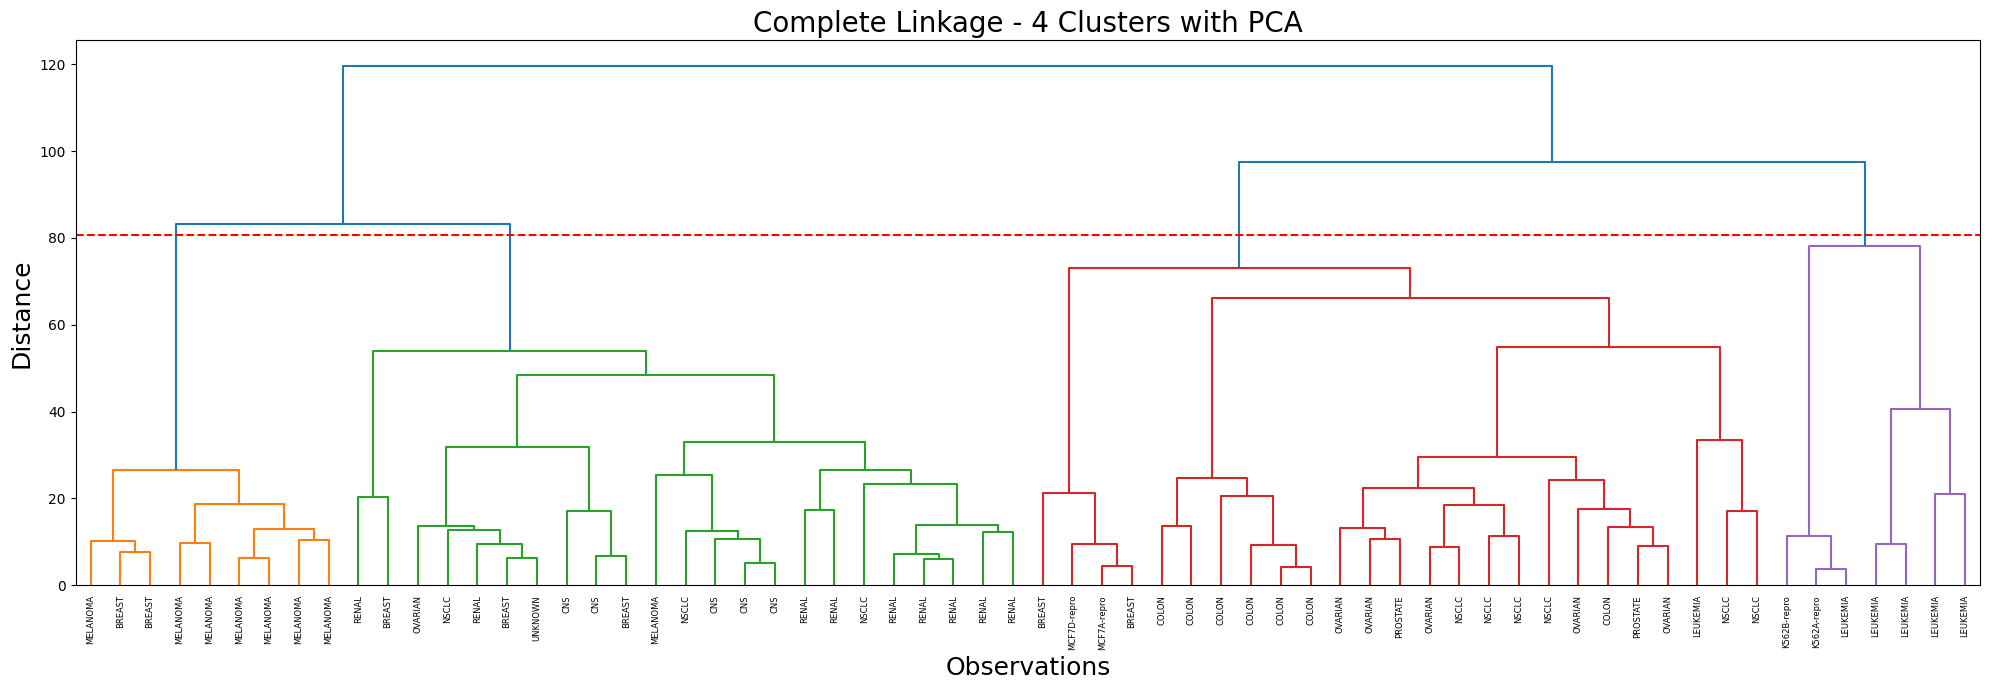

In [46]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 5)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(20, 7))

complete_linkage_pca = linkage(X_pca, method = "complete", metric = "euclidean")
# For cutting 4 clusters
hc_labels_pca = fcluster(complete_linkage_pca, t=4, criterion="maxclust")
threshold = (complete_linkage_pca[-4, 2] + complete_linkage_pca[-3, 2]) / 2

dendrogram(complete_linkage_pca, ax = ax, labels = y, color_threshold = threshold)

ax.axhline(y=threshold, color="red", linestyle="--")
ax.set_title("Complete Linkage - 4 Clusters with PCA", size=20)
ax.set_xlabel("Observations", size=18)
ax.set_ylabel("Distance", size=18)
plt.tight_layout()
plt.show()


7. Compute the internal validation metrics for this PCA-based 4-cluster solution. Do these values indicate better or worse quality than those obtained using the original (non-reduced) data? In addition, compare the agreement between the PCA-based partition and the original partition using at least one external validation metric. Comment on whether dimensionality reduction improved, worsened, or did not change the clustering quality.

**4-Cluster Hierarchical**
Silhouette Score: 0.07884960913370792\
Calinski-Harabasz Index: 5.010292812643681\
Davies-Bouldin Index: 2.1682612357608146\
Adjusted Rand Index: 0.37367774910430185\

**4-Cluster Kmeans**
Silhouette Score: 0.1114481646761114\
Calinski-Harabasz Index: 6.2219018600878595\
Davies-Bouldin Index: 2.1874520321059316\

**4-Cluster PCA Hierarchical**
Silhouette Score: 0.39203946531925216\
Calinski-Harabasz Index: 34.68175294794821\
Davies-Bouldin Index: 0.9550993435623167\
Adjusted Rand Index: 0.19606850671415002

**Based on these results, the pca version of complete linkage has a higher silhouette score and CH index than the rest. In addition, it also acheived a lower DB index than the other two. In conclusion, according to this internal metrics, the pca version performs better than the other two. Based on external metrics, however. The adjusted rand index is lower than previous, indicating a weaker agreement between the non-reduced and reduced data. While dimension reduction improved cluster quality, reduction fundamentally changed the structure of the clusters, making it hard to compare (internal metrics) with the non-reduced model.**

In [48]:
pca_silhouette = silhouette_score(X_pca, hc_labels_pca)
pca_ch = calinski_harabasz_score(X_pca, hc_labels_pca)
pca_db = davies_bouldin_score(X_pca, hc_labels_pca)

print("Silhouette Score:", pca_silhouette)
print("Calinski-Harabasz Index:", pca_ch)
print("Davies-Bouldin Index:", pca_db)

# External
pca_ari = adjusted_rand_score(hc_labels, hc_labels_pca)
print("Adjusted Rand Index:", pca_ari)

Silhouette Score: 0.39203946531925216
Calinski-Harabasz Index: 34.68175294794821
Davies-Bouldin Index: 0.9550993435623167
Adjusted Rand Index: 0.19606850671415002


## Part 3: Clustering gene expression between healthy and diseased groups (35 points)

The following dataset contains gene expression measurements for 40 tissue samples, each measured on 1,000 genes. The first 20 samples come from healthy patients, while the second 20 samples come from a diseased group.

1. Apply hierarchical clustering to the samples using a correlation-based distance. Use complete, average, and single linkage. Plot the resulting dendrogram for each case.

2. Looking at these dendrograms, which linkage criterion seems to provide better separation of the two groups?

3. Why do you think you were not asked to use Ward linkage here?

4. Now, focusing on complete linkage, cut the dendrogram into 2 clusters. Compare this clustering with the known group labels using the Adjusted Rand Index.

5. Use a two-sample t-test (e.g., the `ttest_ind` function from `scipy.stats`) to compute a p-value for each gene assessing its ability to discriminate between the two groups. There are 1000 genes, so apply a Bonferroni correction by using a significance threshold of α/1000 (with α = 0.05). In other words, consider a gene statistically significant if its p-value is less than 0.05/1000. Select all genes that meet this criterion.

6. Reapply hierarchical clustering to the samples, again with complete linkage and correlation-based distance, but now using only the significant genes. Cut the tree into 2 clusters and compute the Adjusted Rand Index with respect to the known labels. Which clustering solution shows better agreement with the true groups?

7. In the previous step, you should observe that clustering using only the significant genes leads to worse agreement with the known labels than using all 1000 genes, even though these genes were selected for their discriminative ability. Now repeat the hierarchical clustering using complete linkage and Euclidean distance on the significant genes. Cut the dendrogram into 2 clusters and compare the results with the known labels. Why does Euclidean distance produce a much better reconstruction than correlation distance in this scenario?

In [5]:
import pandas as pd
import numpy as np

X = pd.read_csv("Lab08-part3_data.csv") #This is the dataset to use
#We know that the first 20 observations correspond to healthy patients, and the remaining 20 to disease. Let's create labels then:
y = np.array(["healthy"]*20 + ["disease"]*20)

In [6]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from scipy.stats import ttest_ind
from sklearn.metrics import adjusted_rand_score

print(X.shape)  # 40 samples x 1,000 genes

(40, 1000)


### 1. Hierarchical clustering with correlation-based distance

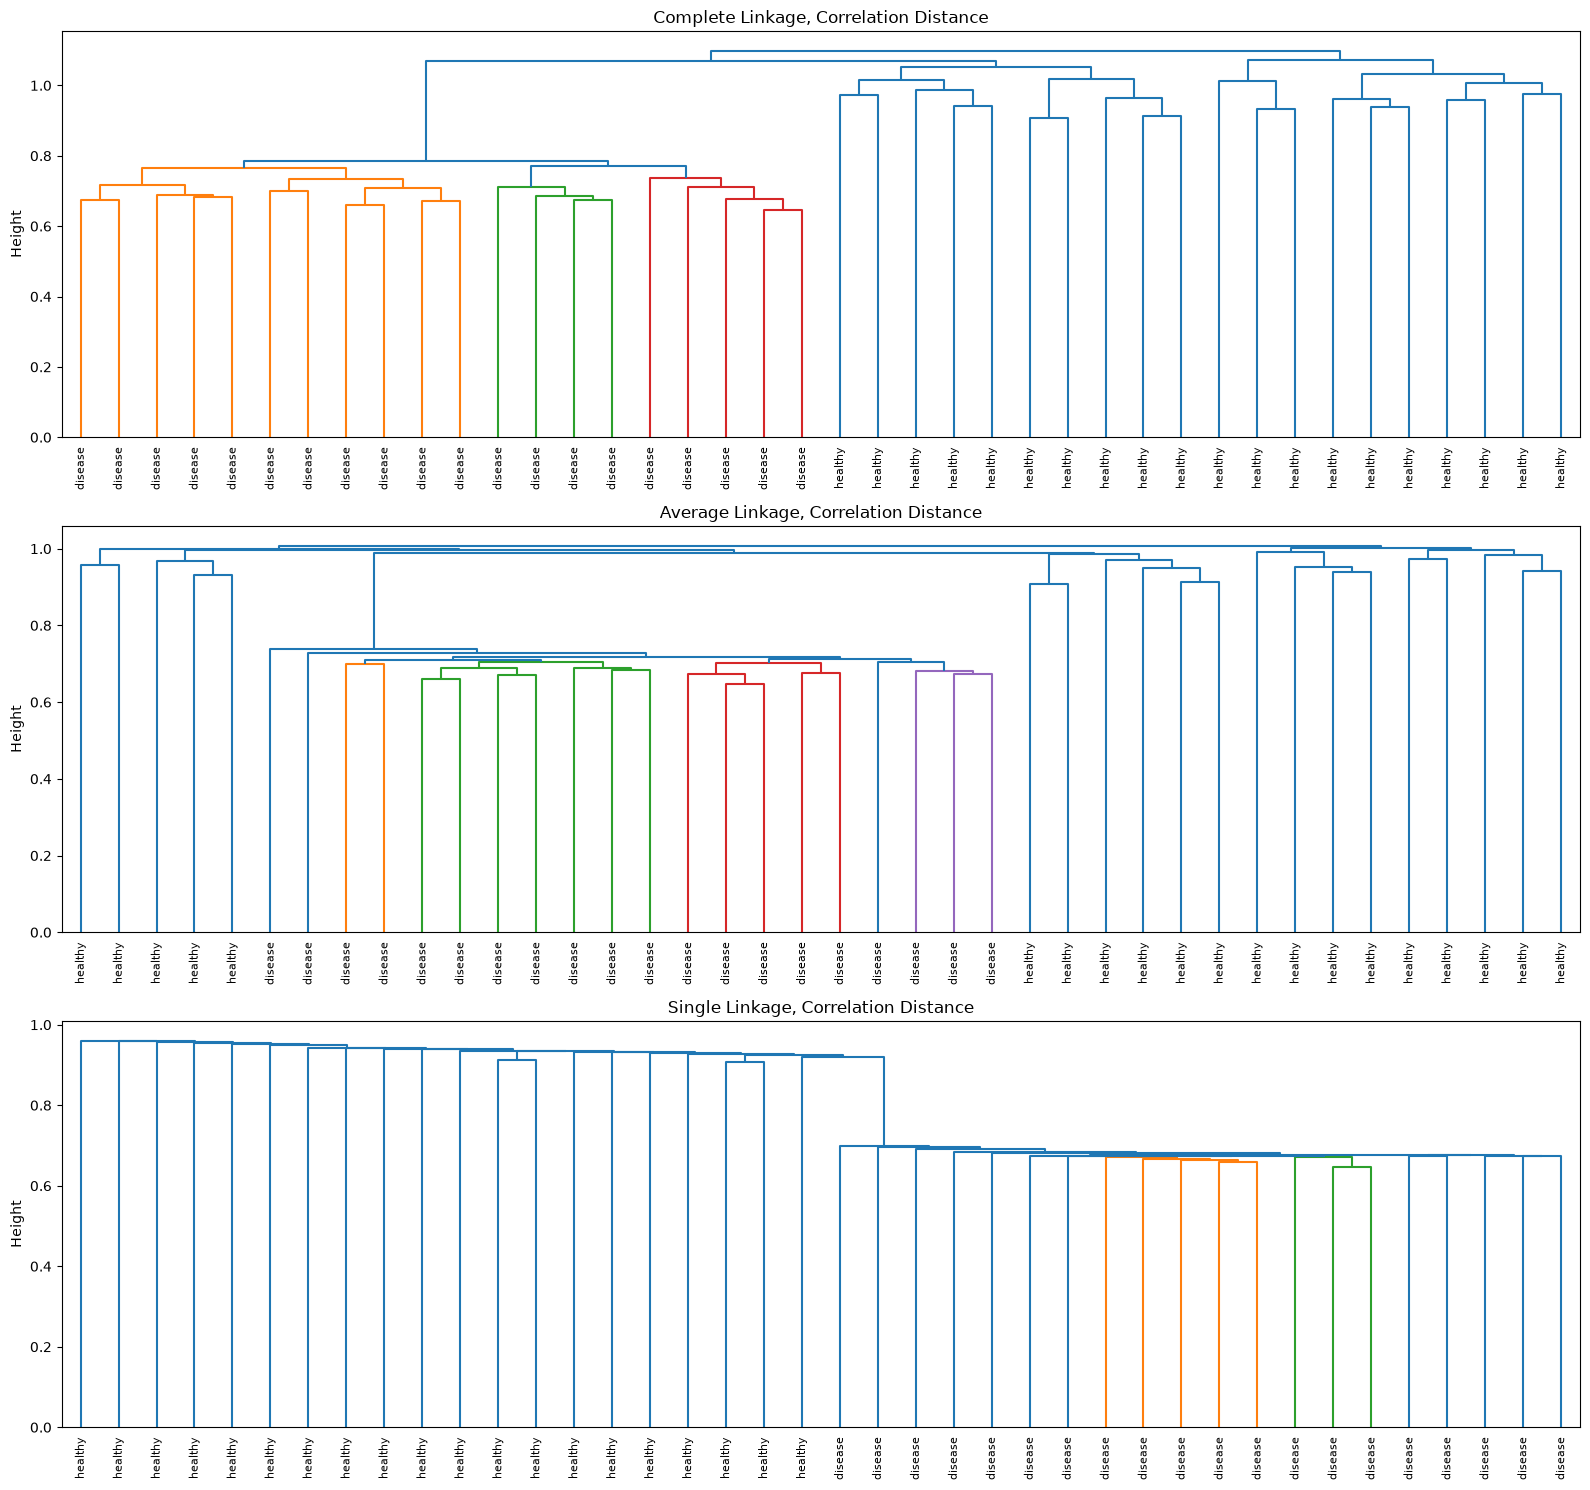

In [7]:
#Correlation distance between samples: 1 - Pearson correlation of their gene expression profiles
D_corr = pdist(X, metric="correlation")

Z3 = {}
fig, axes = plt.subplots(3, 1, figsize=(16, 15))
for ax, method in zip(axes, ["complete", "average", "single"]):
    Z3[method] = linkage(D_corr, method=method)
    dendrogram(Z3[method], labels=y, leaf_rotation=90, ax=ax)
    ax.set_title(f"{method.capitalize()} Linkage, Correlation Distance")
    ax.set_ylabel("Height")
plt.tight_layout()
plt.show()

In [8]:
#How well a 2-cluster cut of each tree matches the true groups
for method, Z in Z3.items():
    c = fcluster(Z, t=2, criterion="maxclust")
    print(f"{method:>8}: ARI = {adjusted_rand_score(y, c):.3f}")
    print(pd.crosstab(y, c, rownames=["Group"], colnames=["Cluster"]), "\n")

complete: ARI = 0.235
Cluster   1   2
Group          
disease  20   0
healthy  10  10 

 average: ARI = 0.188
Cluster   1  2
Group         
disease  20  0
healthy  11  9 

  single: ARI = 0.000
Cluster   1  2
Group         
disease  20  0
healthy  19  1 



### 2. Which linkage separates the groups best?

Complete linkage works best. In its dendrogram, all 20 diseased samples are on one side and all 20 healthy samples are on the other. The diseased samples are very similar to each other, so they join together low in the tree. The healthy samples are less similar, so they join higher up. Average linkage also keeps the diseased samples together, but healthy samples end up on both sides of them. Single linkage adds samples one at a time ("chaining"), so it shows no clear two groups.

### 3. Why not Ward linkage?

Ward linkage only works with Euclidean distance. It joins the clusters that add the least variance, and it measures that variance using Euclidean distance to each cluster's center. We are using a correlation-based distance here, so Ward's results wouldn't make sense.

### 4. Complete linkage cut into 2 clusters

In [9]:
clusters_corr = fcluster(Z3["complete"], t=2, criterion="maxclust")
print(pd.crosstab(y, clusters_corr, rownames=["Group"], colnames=["Cluster"]))
print("\nAdjusted Rand Index:", round(adjusted_rand_score(y, clusters_corr), 3))

Cluster   1   2
Group          
disease  20   0
healthy  10  10

Adjusted Rand Index: 0.235


All 20 diseased samples end up in one cluster, but the healthy samples are split in half: 10 join the diseased cluster and 10 form their own. The Adjusted Rand Index is about 0.24, so the clusters only weakly match the true groups. The healthy samples aren't very similar to each other, so the tree's top split divides the healthy group instead of separating healthy from diseased.

### 5. t-test for each gene with Bonferroni correction

In [10]:
#Two-sample t-test for every gene (column): healthy (first 20 rows) vs. disease (last 20 rows)
t_stat, p_values = ttest_ind(X.iloc[:20], X.iloc[20:], axis=0)

#Bonferroni correction: significant if p < 0.05 / 1000
alpha = 0.05 / X.shape[1]
sig_genes = X.columns[p_values < alpha]
print(f"Bonferroni threshold: {alpha}")
print(f"Number of significant genes: {len(sig_genes)}")
print("Significant genes:", list(sig_genes))

Bonferroni threshold: 5e-05
Number of significant genes: 105
Significant genes: ['10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '500', '501', '502', '503', '504', '505', '506', '507', '508', '510', '511', '512', '513', '514', '515', '516', '518', '519', '520', '521', '522', '523', '524', '525', '526', '527', '528', '529', '530', '531', '532', '533', '534', '535', '536', '537', '538', '539', '540', '541', '542', '543', '544', '545', '546', '547', '548', '549', '550', '551', '552', '553', '554', '555', '556', '557', '558', '559', '560', '561', '562', '563', '564', '565', '566', '567', '568', '569', '570', '571', '573', '574', '575', '576', '577', '578', '579', '580', '581', '582', '583', '585', '586', '587', '588', '589', '590', '591', '592', '594', '595', '596', '597', '598', '599']


### 6. Re-cluster using only the significant genes (correlation distance)

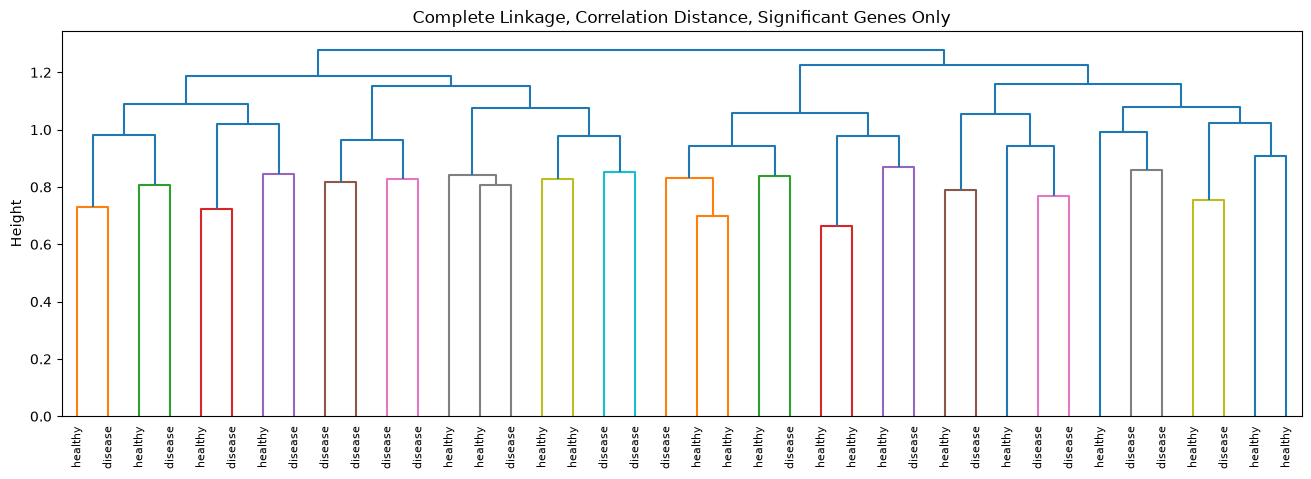

Cluster   1   2
Group          
disease  11   9
healthy   8  12

Adjusted Rand Index: -0.003


In [11]:
X_sig = X[sig_genes]
Z_sig_corr = linkage(pdist(X_sig, metric="correlation"), method="complete")

plt.figure(figsize=(16, 5))
dendrogram(Z_sig_corr, labels=y, leaf_rotation=90)
plt.title("Complete Linkage, Correlation Distance, Significant Genes Only")
plt.ylabel("Height")
plt.show()

clusters_sig_corr = fcluster(Z_sig_corr, t=2, criterion="maxclust")
print(pd.crosstab(y, clusters_sig_corr, rownames=["Group"], colnames=["Cluster"]))
print("\nAdjusted Rand Index:", round(adjusted_rand_score(y, clusters_sig_corr), 3))

Using only the significant genes, the clusters are basically random: each cluster has a mix of healthy and diseased samples, and the ARI is about **0.00**. Clustering with all 1,000 genes (ARI ≈ 0.24) matches the true groups better.

### 7. Re-cluster the significant genes with Euclidean distance

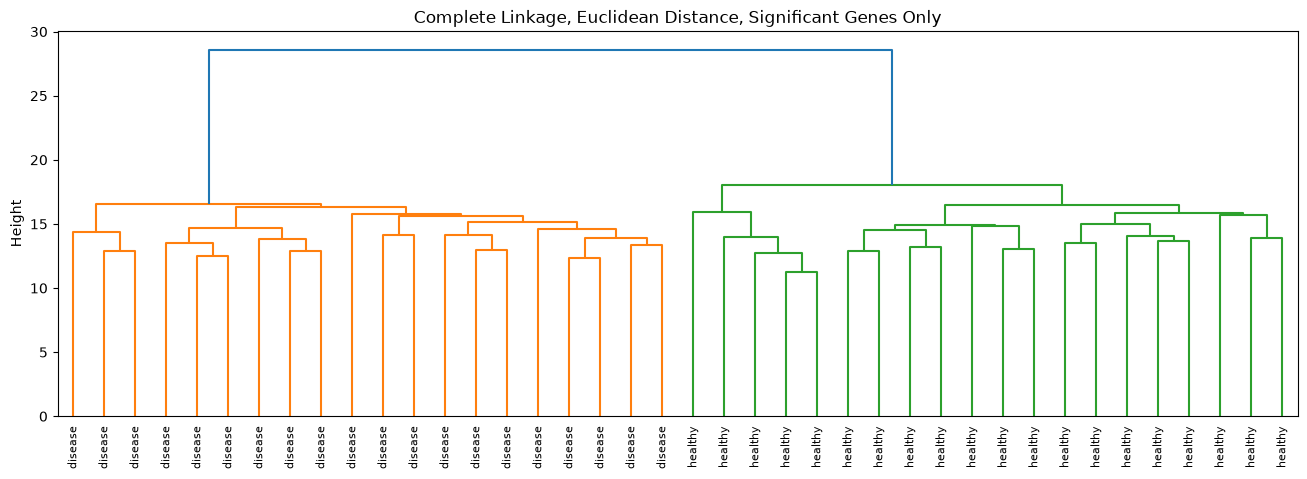

Cluster   1   2
Group          
disease  20   0
healthy   0  20

Adjusted Rand Index: 1.0


In [12]:
Z_sig_euc = linkage(X_sig, method="complete", metric="euclidean")

plt.figure(figsize=(16, 5))
dendrogram(Z_sig_euc, labels=y, leaf_rotation=90)
plt.title("Complete Linkage, Euclidean Distance, Significant Genes Only")
plt.ylabel("Height")
plt.show()

clusters_sig_euc = fcluster(Z_sig_euc, t=2, criterion="maxclust")
print(pd.crosstab(y, clusters_sig_euc, rownames=["Group"], colnames=["Cluster"]))
print("\nAdjusted Rand Index:", round(adjusted_rand_score(y, clusters_sig_euc), 3))

In [13]:
#Average expression of the significant genes in each group
print("Mean expression of significant genes, healthy:", round(X_sig.iloc[:20].values.mean(), 2))
print("Mean expression of significant genes, disease:", round(X_sig.iloc[20:].values.mean(), 2))

Mean expression of significant genes, healthy: -0.01
Mean expression of significant genes, disease: 2.04


With Euclidean distance, the clusters match the true groups perfectly (ARI = 1.0).

Why does Euclidean work better here? The significant genes are simply higher in diseased samples: about 2.0 on average, compared with about 0.0 in healthy samples. Euclidean distance measures how far apart the actual values are, so it easily tells the two groups apart. Correlation distance only looks at the pattern of ups and downs across genes, and it ignores whether values are high or low overall. Since all the significant genes go up together in diseased samples, the pattern looks the same in both groups, and correlation can't tell them apart.

## Part 4: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE